In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('/content/drive/MyDrive/DataScience/Assignments/Data sets/winequality-red.csv')

In [ ]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


1. Load the dataset and handle any missing data by replacing null values with the mean
value of the respective column.

In [5]:
df.shape

(1599, 12)

In [4]:
df.isnull().sum()


,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


The dataset  contains  1599 rows and 12 columns.No missing  values  found .

2. Extract the following columns as vectors: alcohol,citric acid.

In [ ]:
alcohol_vector=df["alcohol"]
citric_acid_vector=df["citric acid"]
print("\nAlcohol vector: ")
print(alcohol_vector.values)
print('\n Citric acid  vector: ')
print(citric_acid_vector.values)


Alcohol vector: 
[ 9.4  9.8  9.8 ... 11.  10.2 11. ]

 Citric acid  vector: 
[0.   0.   0.04 ... 0.13 0.12 0.47]


The alcohol column and citric acid column,were extracted from the dataset as vectors  .

3. Select two features (e.g., alcohol and density) from the dataset and calculate the
covariance matrix using np.cov(X.T), where X is the feature matrix consisting of the
selected columns.

In [7]:
X=df[['density','fixed acidity']]
print('\n Feature matrix: ')
print(X)


 Feature matrix: 
      density  fixed acidity
0     0.99780            7.4
1     0.99680            7.8
2     0.99700            7.8
3     0.99800           11.2
4     0.99780            7.4
...       ...            ...
1594  0.99490            6.2
1595  0.99512            5.9
1596  0.99574            6.3
1597  0.99547            5.9
1598  0.99549            6.0

[1599 rows x 2 columns]


In [ ]:
cov_matrix=np.cov(X.T)
print("\n Covarience matrix:")
print(cov_matrix)



 Covarience matrix:
[[3.56202945e-06 2.19522358e-03]
 [2.19522358e-03 3.03141639e+00]]


The covarience between  density  and fixed acidity is positive (approximately 0.002196),indicating that these two variables  tend to vary in the same direction .

4. Perform eigen decomposition on the covariance matrix you computed in question 3.
Identify and interpret the results:Identify the top 2 eigenvalues of the covariance
matrix,Identify the corresponding eigenvectors.(Score

In [ ]:
eigenvalues,eigenvectors=np.linalg.eig(cov_matrix)
print("\n Eigenvalues: ")
print(eigenvalues)
print("\n Eigenvectors: ")
print(eigenvectors)


 Eigenvalues: 
[1.97234032e-06 3.03141798e+00]

 Eigenvectors: 
[[-9.99999738e-01 -7.24158000e-04]
 [ 7.24158000e-04 -9.99999738e-01]]


In [20]:
index=np.argsort(eigenvalues)[::-1]
eigenvalues=eigenvalues[index]
eigenvectors=eigenvectors[:,index]
print("Eigenvalues: ",eigenvalues)
print("Eigenvectors: ",eigenvectors)

Eigenvalues:  [3.03141798e+00 1.97234032e-06]
Eigenvectors:  [[-7.24158000e-04 -9.99999738e-01]
 [-9.99999738e-01  7.24158000e-04]]


The largest eigenvalue is approximately 3.0314,indicating that the corresponding  eigenvector represents  the direction  of maximum  varience.Density and fixed acidity  have opposite  signs in the second eigenvector ,indicating an opposite direction of variation along this eigenvector.

5. Which wine quality is most common in the dataset? How can you interpret the
distribution of wine quality scores?

In [14]:
df['quality'].value_counts()

,count
quality,
5,681
6,638
7,199
4,53
8,18
3,10


In [15]:
quality_count=df['quality'].value_counts().max()
print("Quality count = ",quality_count)
total =len(df)
probability =quality_count/total
print("Quality probability =  ",probability)

Quality count =  681
Quality probability =   0.425891181988743


Quality  5 has the highest  probability  of approximately 42.6% ,making it the most common wine quality score.

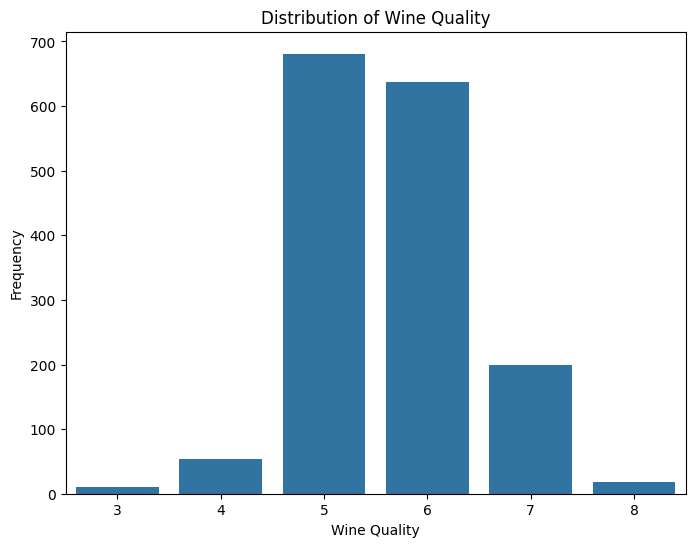

In [16]:
quality_distribution=df['quality'].value_counts()
plt.figure(figsize=(8,6))
sns.barplot(x=quality_distribution.index,y=quality_distribution.values)
plt.xlabel('Wine Quality')
plt.ylabel('Frequency')
plt.title('Distribution of Wine Quality')
plt.show()

INTERPRETATION :

"The most common wine quality score is 5, with 681 observations, followed by quality 6 with 638 observations. Most wines have quality scores of 5 and 6, indicating that the dataset mainly contains medium-quality wines. Very few wines have quality scores of 3 or 8."